# Action-conditional predictor benchmark

**Complete** · 600/600 jobs · ETA 0h 00m 00s · updated 2026-11-11T11:16:36+01:00

Paired coverage through **80,000/80,000 arrivals** per seed across 2026, 2027, 2028. 155,999 scored updates across the seeds.

## RMSE by stream position

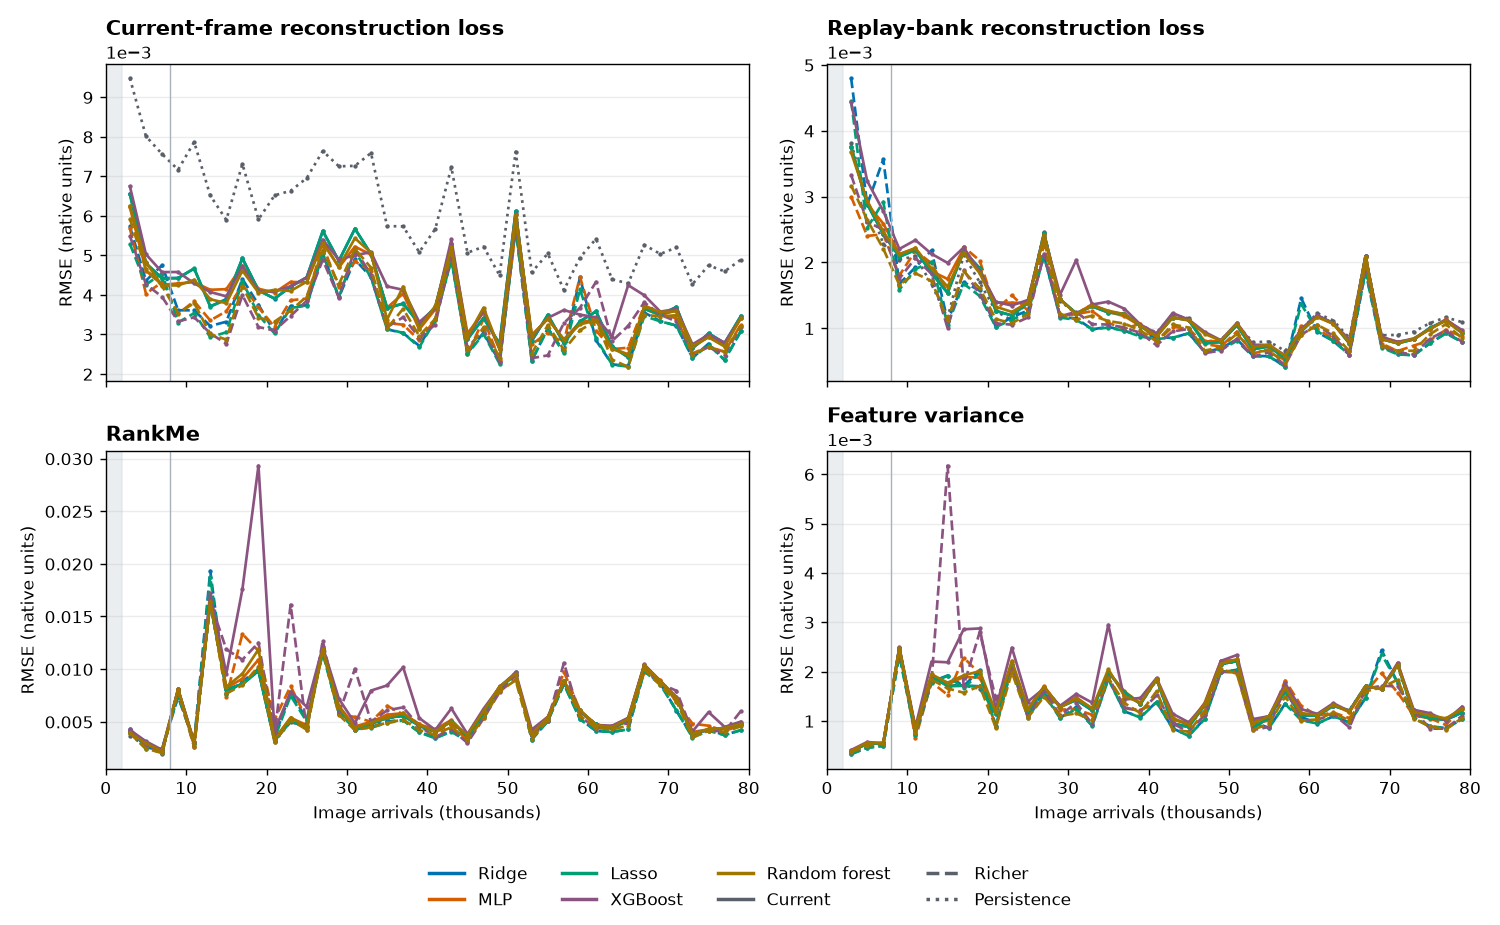

## Pooled RMSE through the latest paired window

| Predictor | Features | Frame loss | Bank loss | RankMe | Variance |
| --- | --- | --- | --- | --- | --- |
 | Persistence | — | 0.00614687 | 0.00153292 | 0.00666713 | 0.00147026 | 
 | Ridge | Current | 0.00407445 | 0.00154086 | 0.00668274 | 0.00147378 | 
 | Ridge | Richer | 0.00363135 | 0.00153846 | 0.00674636 | 0.00137836 | 
 | MLP | Current | 0.00401771 | 0.00156538 | 0.00682413 | 0.00150822 | 
 | MLP | Richer | 0.00371477 | 0.00142313 | 0.00709596 | 0.00142639 | 
 | Lasso | Current | 0.00407146 | 0.00153927 | 0.00668115 | 0.00147331 | 
 | Lasso | Richer | 0.00356474 | 0.00143929 | 0.00664224 | 0.00136099 | 
 | XGBoost | Current | 0.00416223 | 0.00169094 | 0.00894549 | 0.00168176 | 
 | XGBoost | Richer | 0.00363784 | 0.00136129 | 0.00766382 | 0.0017116 | 
 | Random forest | Current | 0.00400502 | 0.00154786 | 0.00686883 | 0.00151521 | 
 | Random forest | Richer | 0.00368554 | 0.00136019 | 0.00648295 | 0.00134928 | 

## Evaluation protocol

All predictors use the same recorded MAE trajectories and the action actually taken. Each predicts the change from the measured pre-action state. RMSE on changes is identical to RMSE on the resulting next-state forecasts. Persistence predicts zero change. The plot scores the 0.25× and 1× update actions, with a separate fit per action. Skips have a known zero change and count toward the arrival axis.

The first 2,000 arrivals supply warm-up. After the fit at 2,000, all models refit at 4,000-arrival boundaries using up to the previous 16,000 arrivals, starting after the 128-arrival bank fill. Scaling uses those past observations. Features for a scored arrival use its pre-action state, the current frame, and previously observed history. The outcome enters model fitting only at a later refit. Dots pool squared errors over 2,000-arrival windows and all seeds. The vertical marker at 8,000 marks the end of MAE calibration.

Current features are the four pre-action measurements. Richer features add temporal differences and averages, frame descriptors, action history, and trailing action responses for 37 inputs in total. Both sets are label-free. Model settings were fixed before scoring. The replay measures predictive accuracy on recorded updates.

In [ ]:
# Run this cell for live refresh in an open notebook.
from IPython.display import clear_output, display, Image, Markdown
from pathlib import Path
import json
import time

folder = Path('C:\\CAFL-E\\analysis\\2026-11-09-one-step-mpc\\predictor-benchmark')
while True:
    try:
        status = json.loads((folder / 'status.json').read_text(encoding='utf-8'))
        chart = (folder / 'rmse.png').read_bytes()
    except (FileNotFoundError, PermissionError):
        time.sleep(2)
        continue
    eta = status['eta_seconds']
    eta_text = f'{eta / 60:.1f} min' if eta is not None else 'estimating'
    clear_output(wait=True)
    display(Markdown(f"**{status['state']}** · {status['completed_jobs']}/{status['total_jobs']} jobs · "
                     f"paired through {status['compared_through']:,} arrivals per seed · ETA {eta_text}"))
    display(Image(data=chart))
    if status['state'] in ('complete', 'failed'):
        if status.get('error'):
            display(Markdown(status['error']))
        break
    time.sleep(10)
